# Etapa 3 – Análisis exploratorio: Airbnb Clark County (Las Vegas)

**Preguntas de negocio que guían el análisis:**
1. ¿Cuál es el precio más adecuado por noche para un anuncio?
2. ¿Qué características le suben el precio a un anuncio (consejos para anfitriones)?
3. ¿Cómo clasificar los anuncios en recomendables o no recomendables?

## 1. Carga de datos
Cargamos el dataset limpio de la Etapa 2 y las librerías para gráficas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

df = pd.read_csv('listings_clark_limpio.csv')
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (16434, 57)


,id,hosts_time_as_host_years,host_is_superhost,host_listings_count,host_has_profile_pic,host_identity_verified,calculated_host_listings_count,latitude,longitude,accommodates,bedrooms,beds,price,minimum_nights,maximum_nights,availability_30,availability_365,estimated_occupancy_l365d,number_of_reviews,number_of_reviews_ltm,reviews_per_month,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,bathrooms_shared,bathrooms,is_exempt,has_license,days_since_last_review,n_amenities,has_pool,has_hot_tub,has_parking,has_kitchen,has_washer,has_workspace,has_self_checkin,has_gym,has_pets,room_type_Hotel room,room_type_Private room,room_type_Shared room,property_type_Condo,property_type_Guesthouse,property_type_Hotel/Resort,property_type_House,property_type_Other,neighbourhood_cleansed_City of Las Vegas,neighbourhood_cleansed_City of Mesquite,neighbourhood_cleansed_City of North Las Vegas,neighbourhood_cleansed_Other,neighbourhood_cleansed_Unincorporated Areas,has_reviews
0,44701,15,0,3,1,1,1,36.11689,-115.16263,8,2.0,3.0,277.0,7.0,7.0,0,15,0,4,0,0.03,5.00,5.00,4.50,5.00,5.00,4.75,4.50,0,2.0,1.0,0.0,980.0,56,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
1,114140,15,0,8,1,1,6,36.10736,-115.16591,4,1.0,2.0,164.4,2.0,1125.0,19,46,0,164,0,0.95,4.64,4.70,4.69,4.56,4.41,4.78,4.63,0,2.0,1.0,0.0,370.0,16,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
2,143096,15,1,1,1,1,1,36.05150,-115.22566,6,3.0,3.0,222.0,3.0,365.0,9,326,138,286,23,1.54,4.65,4.77,4.47,4.93,4.90,4.79,4.71,0,2.5,NaN,NaN,34.0,49,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1
3,200680,15,0,11,1,1,10,36.10361,-115.29155,10,4.0,6.0,327.5,2.0,368.0,30,365,30,158,5,0.88,4.44,4.55,4.43,4.66,4.57,4.62,4.43,0,3.0,NaN,NaN,13.0,36,1,0,1,1,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1
4,201619,15,0,2,1,1,1,36.07780,-115.27517,8,4.0,4.0,490.0,3.0,60.0,26,347,18,127,3,0.69,4.59,4.65,4.60,4.71,4.65,4.68,4.54,0,2.5,0.0,1.0,71.0,75,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1


## 2. Tipos de variables y nulos
Revisamos que todo sea numérico y que los únicos vacíos sean los que dejamos a propósito en la Etapa 2.

In [2]:
print(df.dtypes.value_counts())

nulos = df.isnull().sum()
nulos[nulos > 0]

int64      38
float64    19
Name: count, dtype: int64


review_scores_rating            4338
review_scores_accuracy          4338
review_scores_cleanliness       4338
review_scores_checkin           4339
review_scores_communication     4338
review_scores_location          4339
review_scores_value             4339
is_exempt                      10576
has_license                    10576
days_since_last_review          4338
dtype: int64

## 3. Reconstruir las categorías
En la Etapa 2 las categorías pasaron a columnas de 1 y 0. Para graficar es más fácil tenerlas como texto, así que las reconstruimos en columnas nuevas (no se borran los dummies). La categoría que se quitó con `drop_first` es la que queda cuando todos los dummies valen 0.

In [4]:
def desde_dummies(df, prefijo, base):
    cols = [c for c in df.columns if c.startswith(prefijo + '_')]
    nombres = df[cols].idxmax(axis=1).str.replace(prefijo + '_', '', regex=False)
    return nombres.where(df[cols].sum(axis=1) == 1, base)

df['tipo_habitacion'] = desde_dummies(df, 'room_type', 'Entire home/apt')
df['tipo_propiedad']  = desde_dummies(df, 'property_type', 'Apartment')
df['zona']            = desde_dummies(df, 'neighbourhood_cleansed', 'City of Henderson')

for col in ['tipo_habitacion', 'tipo_propiedad', 'zona']:
    print(df[col].value_counts(), '\n')

tipo_habitacion
Entire home/apt    12014
Private room        4234
Hotel room           158
Shared room           28
Name: count, dtype: int64 

tipo_propiedad
House           6499
Apartment       3764
Hotel/Resort    2777
Condo           2574
Guesthouse       641
Other            179
Name: count, dtype: int64 

zona
Unincorporated Areas       12897
City of Las Vegas           1836
City of North Las Vegas      767
City of Henderson            730
City of Mesquite             185
Other                         19
Name: count, dtype: int64 



Cada variable suma los 16.434 anuncios. La mayoría de anuncios son la vivienda completa (12.014), seguidos por habitación privada (4.234); hotel (158) y habitación compartida (28) son muy pocos. Por tipo de propiedad predominan las casas (6.499), luego apartamentos (3.764), hotel/resort (2.777) y condos (2.574). El 78 % de los anuncios (12.897) está en las zonas no incorporadas, donde está el Strip, y la zona Other tiene solo 19. Los grupos con muy pocos anuncios se veran en las gráficas, pero sus resultados son poco confiables.

## 4. Estadísticas descriptivas
Resumen de las variables numéricas principales: centro (media y mediana), dispersión y rango.

In [5]:
principales = ['price', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'n_amenities',
               'minimum_nights', 'availability_365', 'estimated_occupancy_l365d',
               'number_of_reviews', 'review_scores_rating', 'hosts_time_as_host_years']

desc = df[principales].describe().T
desc['asimetria'] = df[principales].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
price,16434.0,289.78,235.37,28.0,137.67,232.06,360.0,1765.0,2.29
accommodates,16434.0,5.71,3.57,1.0,4.00,4.00,8.0,16.0,1.09
bedrooms,16434.0,2.02,1.54,0.0,1.00,2.00,3.0,10.0,1.24
beds,16434.0,3.06,2.20,1.0,2.00,2.00,4.0,16.0,1.84
bathrooms,16434.0,1.73,0.89,0.0,1.00,2.00,2.0,9.0,1.64
n_amenities,16434.0,40.96,17.56,0.0,27.00,42.00,53.0,112.0,0.04
minimum_nights,16434.0,6.73,10.53,1.0,1.00,2.00,3.0,31.0,1.74
availability_365,16434.0,237.12,114.84,0.0,136.00,267.00,345.0,365.0,-0.54
estimated_occupancy_l365d,16434.0,60.85,81.56,0.0,0.00,12.00,108.0,255.0,1.21
number_of_reviews,16434.0,41.36,84.98,0.0,0.00,6.00,46.0,1963.0,5.44


Precio: el precio típico (mediana) es $232 por noche, pero el promedio sube a $290 porque hay pocos anuncios muy caros. Por eso el precio está sesgado hacia la derecha.
Tamaño: el anuncio típico recibe 4 huéspedes y tiene 2 habitaciones, 2 camas y 2 baños. La mayoría son inmuebles pequeños y pocos son muy grandes.
Comodidades: un anuncio típico tiene 42 comodidades. Es la única variable equilibrada (sin sesgo).
Noches mínimas: la mayoría pide 2 noches o menos; pocos piden estadías largas.
Ocupación: el anuncio típico solo se rentó 12 noches en el último año y el 25 % no se rentó ninguna. Muchos anuncios están publicados pero casi no se usan.
Reseñas: el anuncio típico tiene 6 reseñas, pero unos pocos tienen cientos (máximo 1.963).
Calificación: el 74 % de los anuncios tiene reseñas. La calificación típica es 4,90 de 5 y 3 de cada 4 anuncios tienen 4,76 o más. Casi todos califican alto, así que para decir que un anuncio es "recomendable" hay que pedir una calificación muy alta.
Anfitriones: llevan en promedio 4 a 5 años en Airbnb, con desde 0 hasta 15 años.

## 5. Variable objetivo: precio
Miramos cómo se distribuye el precio por noche. Si está muy sesgado, conviene usar su logaritmo en los modelos.

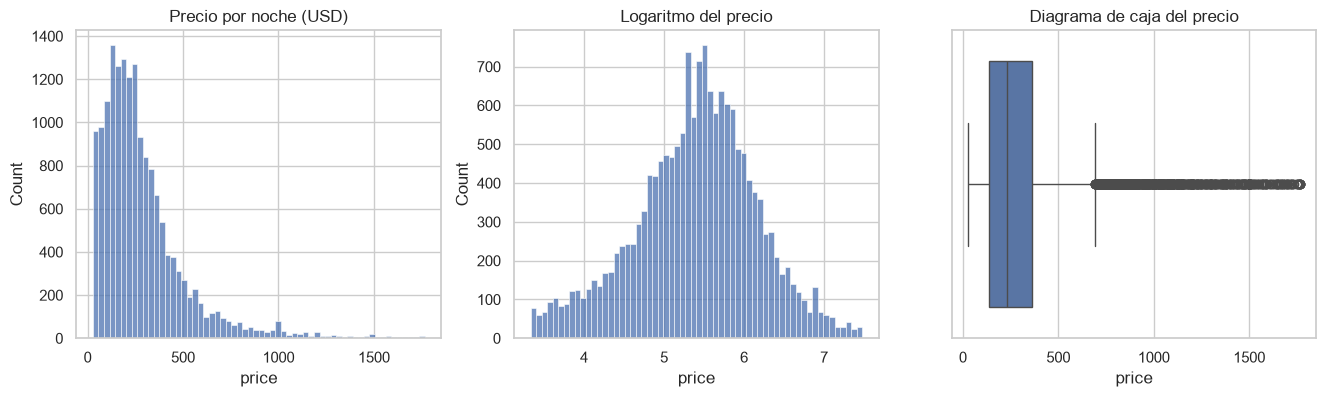

Asimetría precio: 2.29
Asimetría log(precio): -0.23


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['price'], bins=60, ax=ax[0])
ax[0].set_title('Precio por noche (USD)')

sns.histplot(np.log(df['price']), bins=60, ax=ax[1])
ax[1].set_title('Logaritmo del precio')

sns.boxplot(x=df['price'], ax=ax[2])
ax[2].set_title('Diagrama de caja del precio')
plt.show()

print("Asimetría precio:", round(df['price'].skew(), 2))
print("Asimetría log(precio):", round(np.log(df['price']).skew(), 2))

La mayoría de anuncios cuesta entre $100 y $400 por noche, con pocos anuncios caros que llegan hasta $1.765 (asimetría 2,29).
Con el logaritmo el precio queda casi simétrico (asimetría −0,23). Por eso en la regresión se usará el logaritmo del precio.
Los puntos sobre $700 en la caja no son errores: son casas grandes o de lujo.

## 6. Distribución de las variables numéricas
Histogramas y diagramas de caja de las variables del inmueble, la disponibilidad y las reseñas.

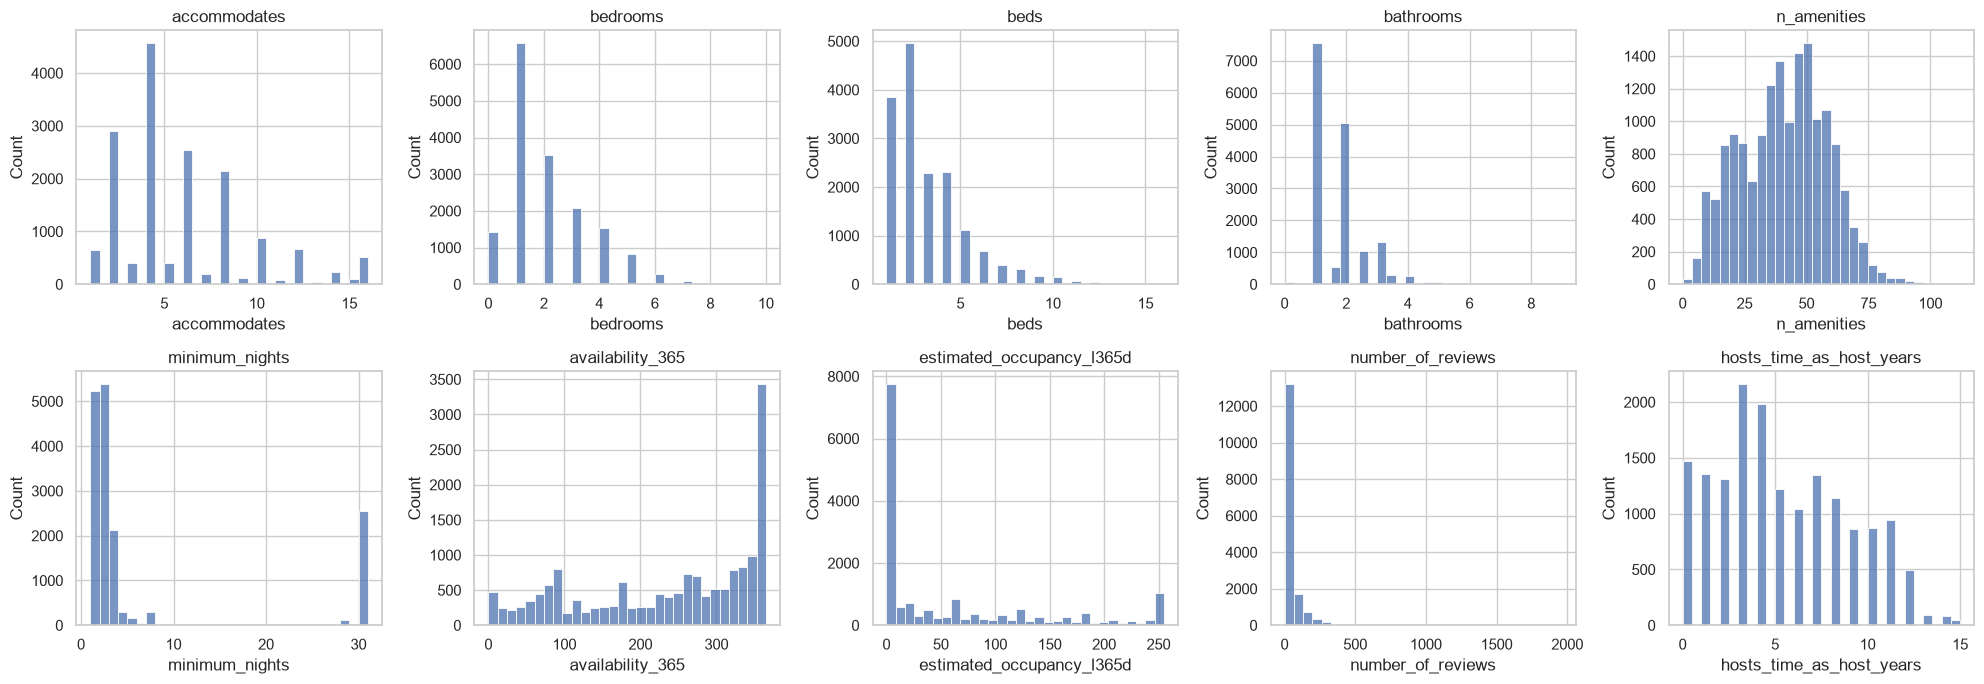

In [7]:
vars_hist = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'n_amenities',
             'minimum_nights', 'availability_365', 'estimated_occupancy_l365d',
             'number_of_reviews', 'hosts_time_as_host_years']

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for col, ax in zip(vars_hist, axes.flat):
    sns.histplot(df[col].dropna(), bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


Tamaño: lo más común es 4 huéspedes, 1 habitación y 1 o 2 baños. Los huéspedes se agrupan en números pares (2, 4, 6, 8) y hay unos 1.400 estudios (0 habitaciones).
Comodidades: es la única variable con forma de campana, centrada en unas 45.
Noches mínimas: hay dos grupos: la mayoría pide de 1 a 3 noches, pero unos anuncios piden 30 noches (rentas mensuales).
Ocupación y reseñas: casi la mitad de los anuncios no se rentó en el último año y la mayoría tiene muy pocas reseñas; unos tienen el calendario libre todo el año. Hay muchos anuncios publicados pero inactivos.

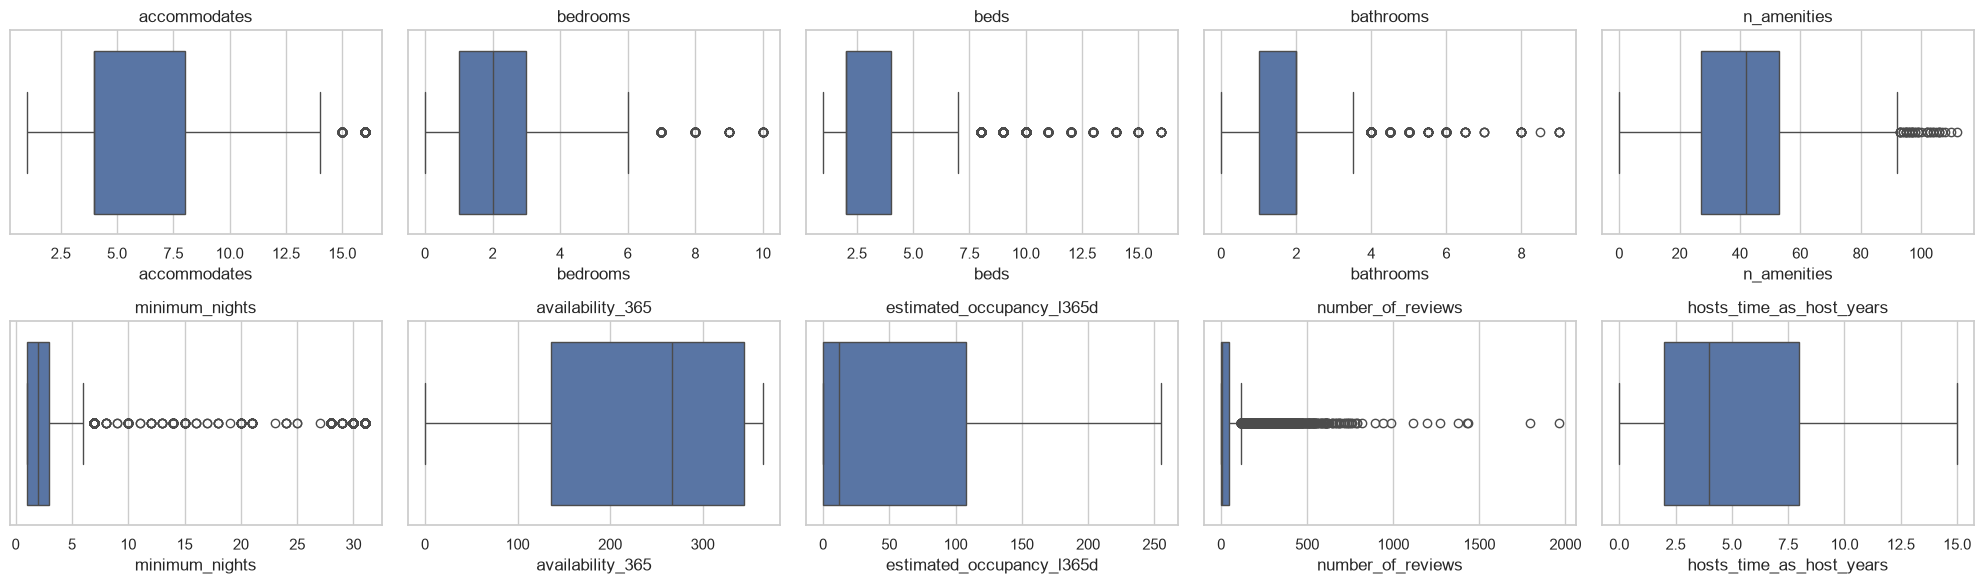

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
for col, ax in zip(vars_hist, axes.flat):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

salen puntos atípicos en camas (más de 7), baños (más de 3,5), noches mínimas (más de 6, incluye las rentas de 30 noches) y reseñas (más de unas 120). Son valores reales de inmuebles grandes o muy populares, no errores, así que se dejan. Disponibilidad, ocupación y años del anfitrión no tienen atípicos.

## 7. Precio según categorías
Comparamos el precio entre tipos de habitación, tipos de propiedad y zonas con diagramas de caja y de violín. El violín muestra además la forma de la distribución.

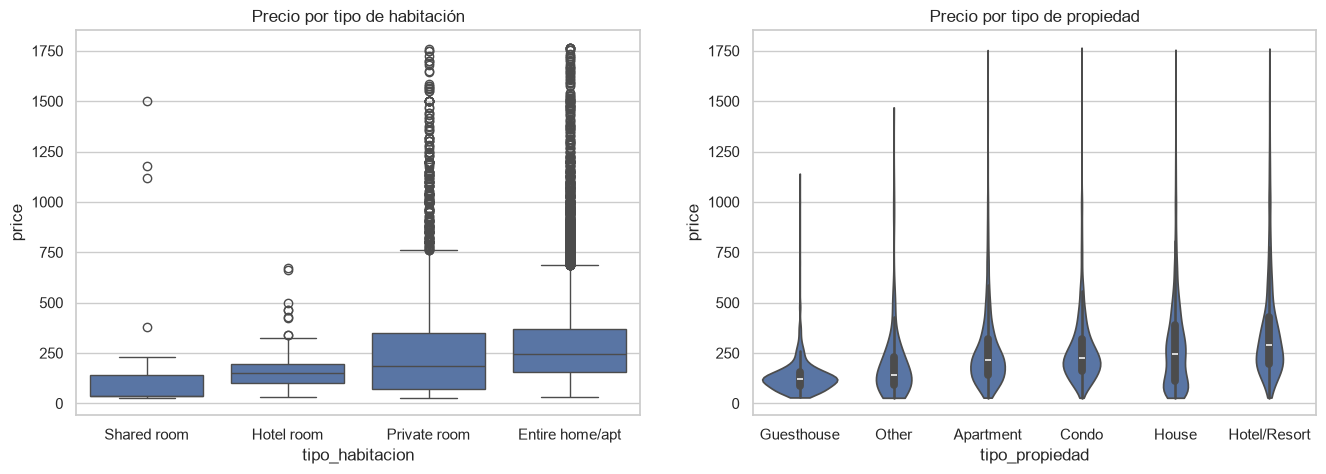

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

orden = df.groupby('tipo_habitacion')['price'].median().sort_values().index
sns.boxplot(data=df, x='tipo_habitacion', y='price', order=orden, ax=ax[0])
ax[0].set_title('Precio por tipo de habitación')

orden = df.groupby('tipo_propiedad')['price'].median().sort_values().index
sns.violinplot(data=df, x='tipo_propiedad', y='price', order=orden, cut=0, ax=ax[1])
ax[1].set_title('Precio por tipo de propiedad')
plt.show()

Tipo de habitación:la vivienda completa es la más cara, seguida de la habitación privada; hotel y compartida son las más baratas. La habitación privada tiene muchísimos precios altos.
Tipo de propiedad: Hotel/Resort tiene la mediana más alta y Guesthouse la más baja. Casa es la más dispersa: tiene desde casas pequeñas baratas hasta mansiones.

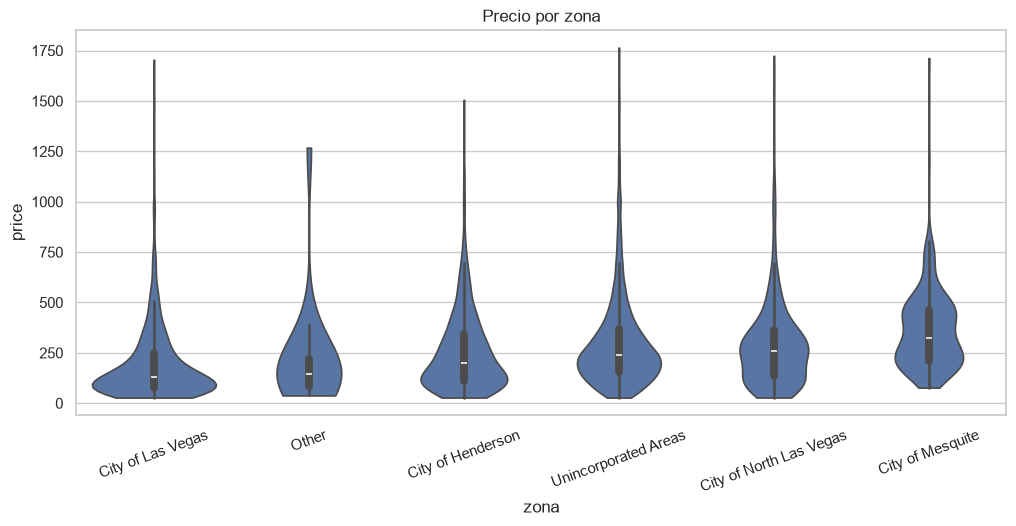

In [10]:
orden = df.groupby('zona')['price'].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.violinplot(data=df, x='zona', y='price', order=orden, cut=0)
plt.xticks(rotation=20)
plt.title('Precio por zona')
plt.show()

In [11]:
tabla = []
for col in ['tipo_habitacion', 'tipo_propiedad', 'zona']:
    t = df.groupby(col)['price'].agg(['count', 'median', 'mean']).round(0)
    t.index = col + ': ' + t.index
    tabla.append(t)
pd.concat(tabla).rename(columns={'count': 'anuncios', 'median': 'mediana', 'mean': 'media'})

,anuncios,mediana,media
tipo_habitacion: Entire home/apt,12014,243.0,301.0
tipo_habitacion: Hotel room,158,149.0,167.0
tipo_habitacion: Private room,4234,188.0,262.0
tipo_habitacion: Shared room,28,39.0,203.0
tipo_propiedad: Apartment,3764,213.0,267.0
tipo_propiedad: Condo,2574,227.0,275.0
tipo_propiedad: Guesthouse,641,120.0,134.0
tipo_propiedad: Hotel/Resort,2777,288.0,365.0
tipo_propiedad: House,6499,246.0,294.0
tipo_propiedad: Other,179,141.0,195.0


Tipo de habitación: rentar la vivienda completa es lo más caro (mediana $243), seguido de la habitación privada ($188), la de hotel ($149) y la compartida ($39). La habitación privada tiene muchos precios altos, probablemente habitaciones en resorts del Strip.
Tipo de propiedad: Hotel/Resort es lo más caro ($288), seguido de casa ($246), condo ($227) y apartamento ($213). Guesthouse es lo más barato ($120).
Zona: Mesquite es la más cara ($322) y City of Las Vegas la más barata ($128). Las zonas no incorporadas, donde está el Strip, tienen $241. Parte de estas diferencias puede deberse al tamaño de los inmuebles, y se revisa después.
En todos los grupos la media es mayor que la mediana: en cada categoría hay unos pocos anuncios muy caros.

## 8. Precio frente a variables numéricas
Diagramas de dispersión del precio contra el tamaño del inmueble y las comodidades. Usamos puntos transparentes porque hay muchos anuncios, y una línea con la mediana para ver la tendencia.

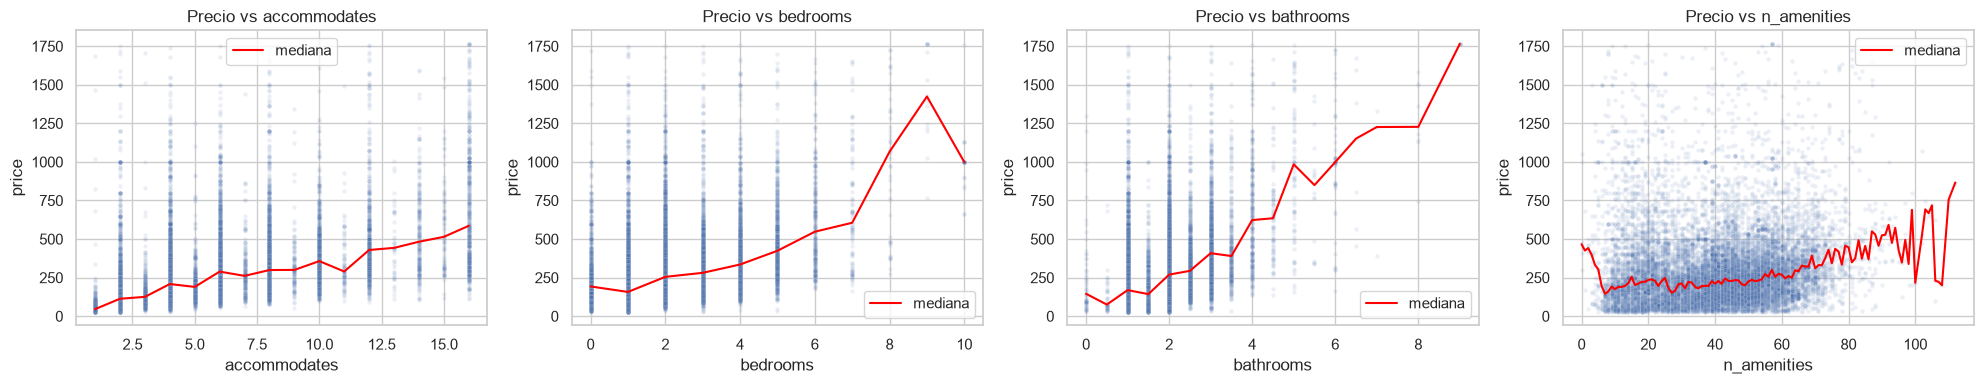

In [12]:
vars_disp = ['accommodates', 'bedrooms', 'bathrooms', 'n_amenities']

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for col, ax in zip(vars_disp, axes):
    sns.scatterplot(data=df, x=col, y='price', alpha=0.1, s=10, ax=ax)
    df.groupby(col)['price'].median().plot(ax=ax, color='red', label='mediana')
    ax.set_title(f'Precio vs {col}')
    ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Mediana del precio según número de huéspedes
df.groupby('accommodates')['price'].agg(['count', 'median']).round(0).T

accommodates,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,644.0,2909.0,398.0,4578.0,394.0,2539.0,197.0,2150.0,117.0,880.0,83.0,666.0,44.0,232.0,91.0,512.0
median,46.0,113.0,125.0,208.0,190.0,289.0,261.0,299.0,300.0,357.0,290.0,429.0,443.0,483.0,514.0,586.0



Huéspedes: el precio sube con la capacidad: la mediana pasa de \$46 (1 huésped) a \$113 (2), \$208 (4), \$289 (6) y \$586 (16). Es la relación más clara con el precio.
Habitaciones y baños: también suben el precio de forma constante. Con más de 7 habitaciones o 6 baños la línea salta porque hay muy pocos anuncios.
Comodidades: el precio casi no cambia entre 10 y 60 comodidades (cerca de \$200–250); solo sube en los anuncios con más de 60, que suelen ser casas grandes.
A mayor tamaño, más dispersión de precios: dos casas del mismo tamaño pueden tener precios muy distintos. Esto refuerza usar el logaritmo del precio.

## 9. Correlaciones
Calculamos la correlación de cada variable con el precio. Usamos **Spearman** porque el precio está sesgado y Spearman mide si dos variables suben juntas, sin exigir una relación lineal.

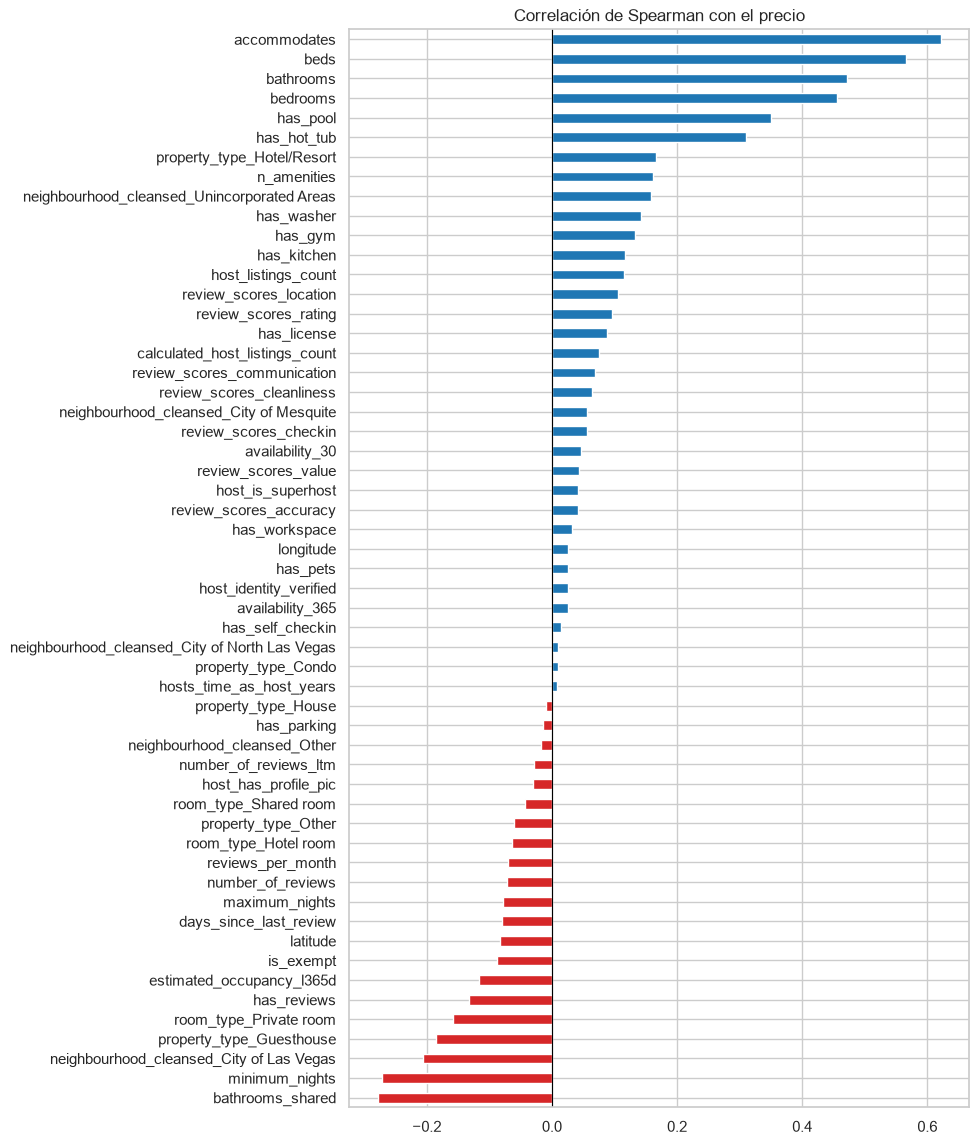

In [15]:
numericas = df.select_dtypes('number').drop(columns=['id'])
corr_precio = numericas.corr(method='spearman')['price'].drop('price').sort_values()

plt.figure(figsize=(8, 14))
corr_precio.plot(kind='barh', color=np.where(corr_precio > 0, 'tab:blue', 'tab:red'))
plt.title('Correlación de Spearman con el precio')
plt.axvline(0, color='black', lw=0.8)
plt.show()

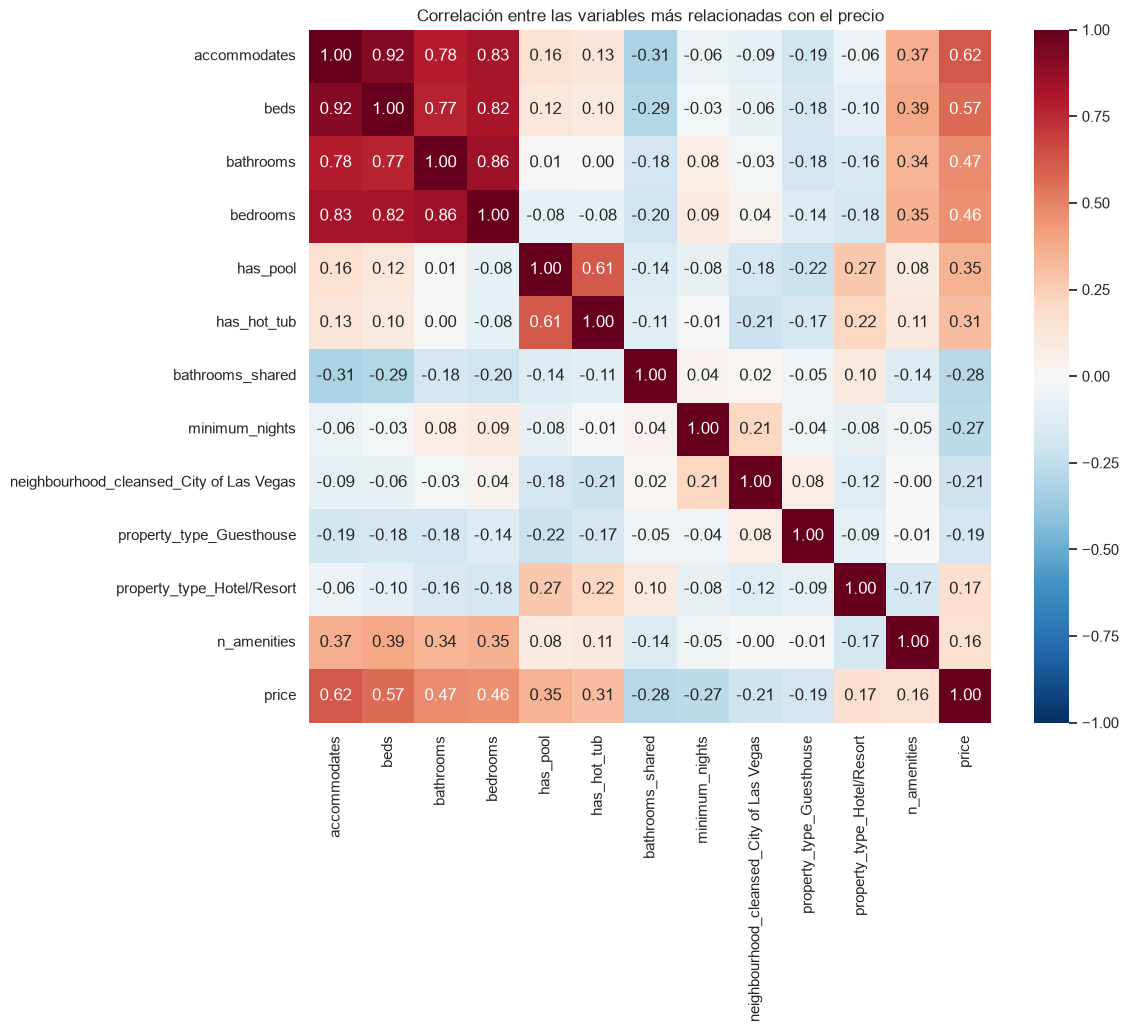

In [16]:
# Mapa de calor entre las variables más relacionadas con el precio
top = corr_precio.abs().sort_values(ascending=False).head(12).index.tolist() + ['price']

plt.figure(figsize=(11, 9))
sns.heatmap(numericas[top].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlación entre las variables más relacionadas con el precio')
plt.show()


Lo que más sube el precio: el tamaño, es decir huéspedes (0,62), camas (0,57), baños (0,47) y habitaciones (0,46). Le siguen la piscina (0,35) y el jacuzzi (0,31), que pesan más que Lo que baja el precio baño compartido (−0,28), más noches mínimas (−0,27), estar en City of Las Vegas (−0,21), ser guesthouse (−0,19) y ser habitación privada (−0,16).
Las calificaciones casi no se relacionan con el precio (alrededor de 0,1): un anuncio caro no es necesariamente mejor calificado.
Variables muy parecidas entre sí: huéspedes y camas (0,92), habitaciones y baños (0,86), huéspedes y habitaciones (0,83). Miden casi lo mismo (el tamaño), así que en la regresión no conviene usarlas todas juntas. Piscina y jacuzzi también van juntos (0,61).

## 10. Comodidades (amenities)
Comparamos la mediana del precio de los anuncios con y sin cada comodidad. Queremos revisar el efecto real de cada comodidad, por eso también comparamos el precio por huésped para qeu el tamaño no influya.

In [17]:
amenities = ['has_pool', 'has_hot_tub', 'has_parking', 'has_kitchen', 'has_washer',
             'has_workspace', 'has_self_checkin', 'has_gym', 'has_pets']
precio_huesped = df['price'] / df['accommodates']

filas = []
for a in amenities:
    con, sin = df[a] == 1, df[a] == 0
    filas.append({
        'comodidad': a,
        '% anuncios': round(df[a].mean() * 100),
        'mediana con': df.loc[con, 'price'].median(),
        'mediana sin': df.loc[sin, 'price'].median(),
        'por huésped con': round(precio_huesped[con].median(), 1),
        'por huésped sin': round(precio_huesped[sin].median(), 1),
    })
amen = pd.DataFrame(filas)
amen['diferencia %'] = ((amen['mediana con'] / amen['mediana sin'] - 1) * 100).round(0)
amen.sort_values('diferencia %', ascending=False)

,comodidad,% anuncios,mediana con,mediana sin,por huésped con,por huésped sin,diferencia %
0,has_pool,68,262.780,146.50,51.0,36.5,79.0
1,has_hot_tub,50,273.000,179.74,53.3,39.3,52.0
3,has_kitchen,91,237.900,160.00,45.0,62.0,49.0
4,has_washer,75,251.000,192.75,43.4,52.0,30.0
7,has_gym,37,248.800,215.83,52.8,41.4,15.0
8,has_pets,24,242.000,229.00,38.1,48.8,6.0
6,has_self_checkin,70,235.785,225.00,44.5,50.0,5.0
5,has_workspace,64,234.000,227.91,45.4,47.0,3.0
2,has_parking,81,232.000,234.25,44.8,53.6,-1.0


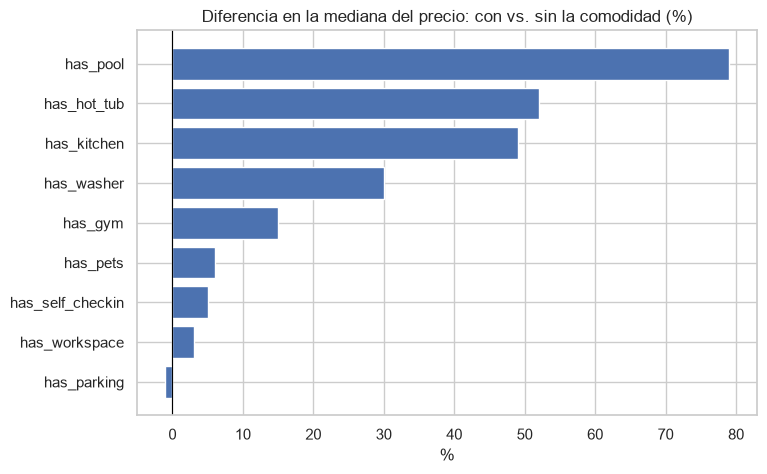

In [18]:
orden = amen.sort_values('diferencia %')
plt.figure(figsize=(8, 5))
plt.barh(orden['comodidad'], orden['diferencia %'])
plt.axvline(0, color='black', lw=0.8)
plt.title('Diferencia en la mediana del precio: con vs. sin la comodidad (%)')
plt.xlabel('%')
plt.show()


Piscina, jacuzzi y gimnasio sí suben el precio: con piscina la mediana es 79 % más alta ($263 vs. $147) y se mantiene por huésped ($51 vs. $37). Lo mismo con jacuzzi ($53 vs. $39 por huésped) y gimnasio ($53 vs. $41 por huésped).
Cocina y lavadora parecen subir el precio, pero es por el tamaño: en total suben 49 % y 30 %, pero por huésped el precio es menor (cocina $45 vs. $62). 
Mascotas, self check-in, espacio de trabajo y parqueadero no cambian el precio: (diferencias de −1 % a 6 %, y por huésped no suben).
En este sentido, las comodidades que agregan valor son las de "lujo" (piscina, jacuzzi, gimnasio); las básicas ya las tiene casi todo el mundo y no marcan diferencia.

## 11. Ubicación
Graficamos los anuncios con su latitud y longitud, coloreados por precio (en logaritmo para que los colores se distingan). Después calculamos la distancia de cada anuncio al centro del Strip de Las Vegas.

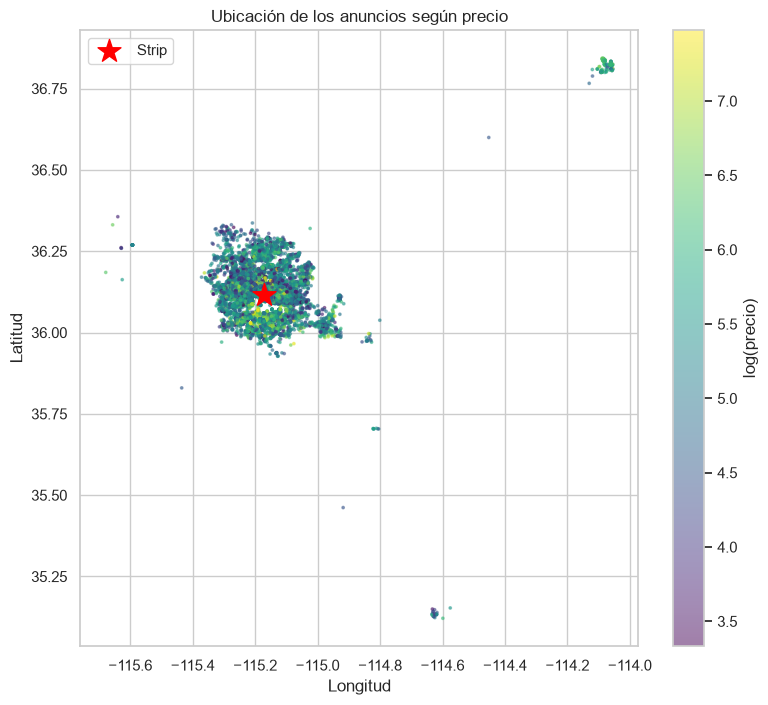

In [19]:
plt.figure(figsize=(9, 8))
plt.scatter(df['longitude'], df['latitude'], c=np.log(df['price']), cmap='viridis', s=3, alpha=0.5)
plt.colorbar(label='log(precio)')
plt.scatter(-115.1728, 36.1147, color='red', marker='*', s=300, label='Strip')
plt.legend()
plt.title('Ubicación de los anuncios según precio')
plt.xlabel('Longitud'); plt.ylabel('Latitud')
plt.show()

In [20]:
# Distancia en km al centro del Strip (fórmula de haversine)
lat0, lon0 = np.radians(36.1147), np.radians(-115.1728)
lat, lon = np.radians(df['latitude']), np.radians(df['longitude'])
a = np.sin((lat - lat0) / 2)**2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2)**2
df['dist_strip_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

df['dist_strip_km'].describe().round(1)

count    16434.0
mean         7.9
std         14.4
min          0.1
25%          1.4
50%          5.2
75%          9.8
max        127.6
Name: dist_strip_km, dtype: float64

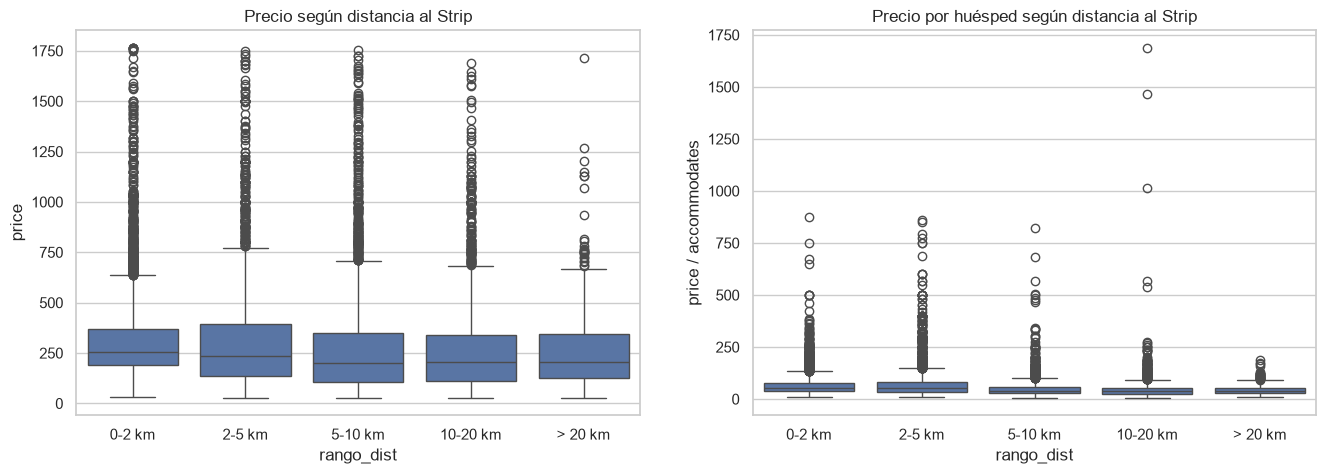

,count,median
rango_dist,,
0-2 km,4952,253.0
2-5 km,3136,236.0
5-10 km,4366,200.0
10-20 km,3384,208.0
> 20 km,596,206.0


In [21]:
df['rango_dist'] = pd.cut(df['dist_strip_km'], bins=[0, 2, 5, 10, 20, 500],
                          labels=['0-2 km', '2-5 km', '5-10 km', '10-20 km', '> 20 km'])

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x='rango_dist', y='price', ax=ax[0])
ax[0].set_title('Precio según distancia al Strip')
sns.boxplot(data=df, x='rango_dist', y=precio_huesped, ax=ax[1])
ax[1].set_title('Precio por huésped según distancia al Strip')
ax[1].set_ylabel('price / accommodates')
plt.show()

df.groupby('rango_dist', observed=True)['price'].agg(['count', 'median']).round(0)


Mapa: casi todos los anuncios están en el área metropolitana de Las Vegas, alrededor del Strip; los más caros (amarillo) se concentran cerca y al sur del Strip. Hay grupos pequeños lejos, arriba a la derecha y abajo.
Distancia: la mitad de los anuncios está a menos de 5,2 km del Strip y el 30 % a menos de 2 km.
Precio: cerca del Strip (0–2 km) la mediana es $253; a partir de 5 km baja a unos $200–208, es decir, cerca de un 20 % menos.
Precio por huésped: también es más alto a menos de 5 km del Strip, así que la ubicación sí suma valor por sí misma, no solo por el tamaño. Aun así, su efecto es menor que el del tamaño del inmueble.

## 12. Anfitrión y licencia
Revisamos si el precio cambia según el tipo de anfitrión: superhost, anfitriones con muchos anuncios (profesionales) y la licencia.

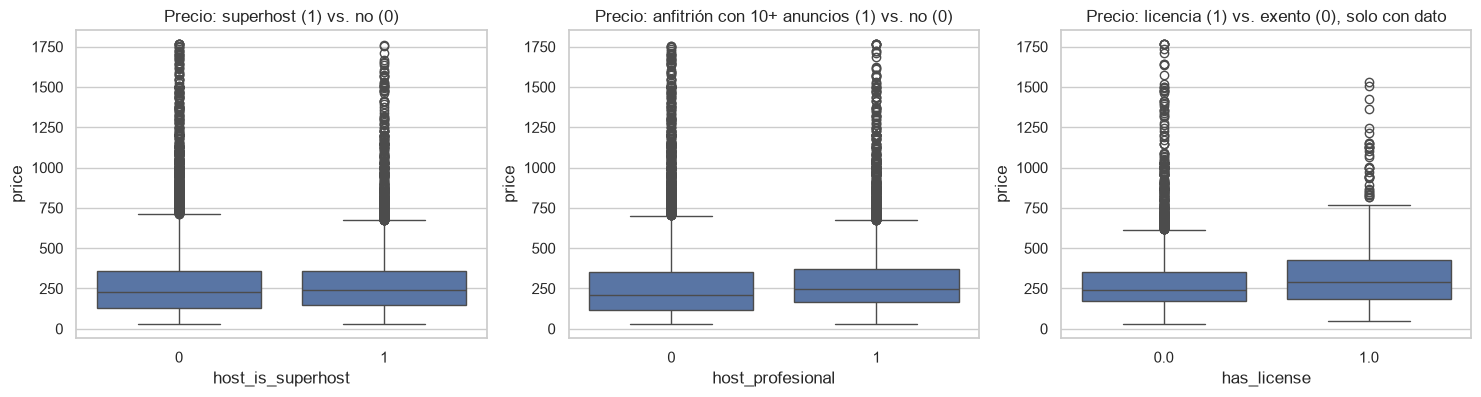

In [22]:
df['host_profesional'] = (df['calculated_host_listings_count'] >= 10).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(data=df, x='host_is_superhost', y='price', ax=ax[0])
ax[0].set_title('Precio: superhost (1) vs. no (0)')
sns.boxplot(data=df, x='host_profesional', y='price', ax=ax[1])
ax[1].set_title('Precio: anfitrión con 10+ anuncios (1) vs. no (0)')
sns.boxplot(data=df.dropna(subset=['has_license']), x='has_license', y='price', ax=ax[2])
ax[2].set_title('Precio: licencia (1) vs. exento (0), solo con dato')
plt.show()

In [23]:
for col in ['host_is_superhost', 'host_profesional', 'has_license']:
    print(df.groupby(col)['price'].agg(['count', 'median']).round(0), '\n')

                   count  median
host_is_superhost               
0                   8912   225.0
1                   7522   238.0 

                  count  median
host_profesional               
0                  8767   211.0
1                  7667   248.0 

             count  median
has_license               
0.0           4869   241.0
1.0            989   291.0 



Superhost: casi la mitad de los anuncios (46 %) es de superhosts, pero cobran casi lo mismo ($238 vs. $225, solo 6 % más). Ser superhost no sube mucho el precio.
Anfitrión profesional: el 47 % de los anuncios es de anfitriones con 10 o más anuncios (empresas), y cobran más ($248 vs. $211, 18 % más).
Licencia: los que tienen licencia cobran más ($291 vs. $241 de los exentos, 21 % más), pero son pocos (989) y solo el 36 % de los anuncios tiene este dato, así que se usa con cuidado.

## 13. Reseñas y calificaciones
Solo los anuncios con reseñas tienen calificaciones, así que este paso usa `has_reviews = 1`. Estas variables son la base para definir qué anuncio es recomendable.

In [28]:

# Corrección: una calificación de comunicación pasa de 5 (máximo de la escala)
df['review_scores_communication'] = df['review_scores_communication'].clip(upper=5)

con_res = df[df['has_reviews'] == 1].copy()
print("Anuncios con reseñas:", len(con_res), f"({len(con_res)/len(df):.1%})")

scores = [c for c in df.columns if c.startswith('review_scores_')]
con_res[scores].describe().round(2)

Anuncios con reseñas: 12096 (73.6%)


,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
count,12096.00,12096.00,12096.00,12095.00,12096.00,12095.00,12095.00
mean,4.79,4.81,4.79,4.85,4.86,4.80,4.75
std,0.41,0.40,0.39,0.38,0.37,0.35,0.42
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,4.76,4.79,4.74,4.86,4.86,4.77,4.71
50%,4.90,4.91,4.89,4.95,4.96,4.89,4.85
75%,5.00,5.00,5.00,5.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00


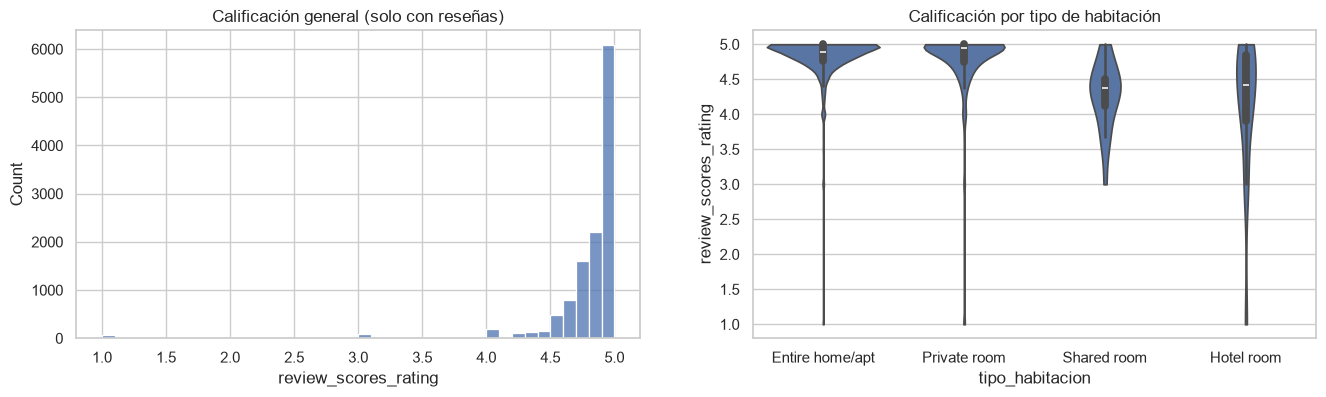

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(con_res['review_scores_rating'], bins=40, ax=ax[0])
ax[0].set_title('Calificación general (solo con reseñas)')
sns.violinplot(data=con_res, x='tipo_habitacion', y='review_scores_rating', cut=0, ax=ax[1])
ax[1].set_title('Calificación por tipo de habitación')
plt.show()

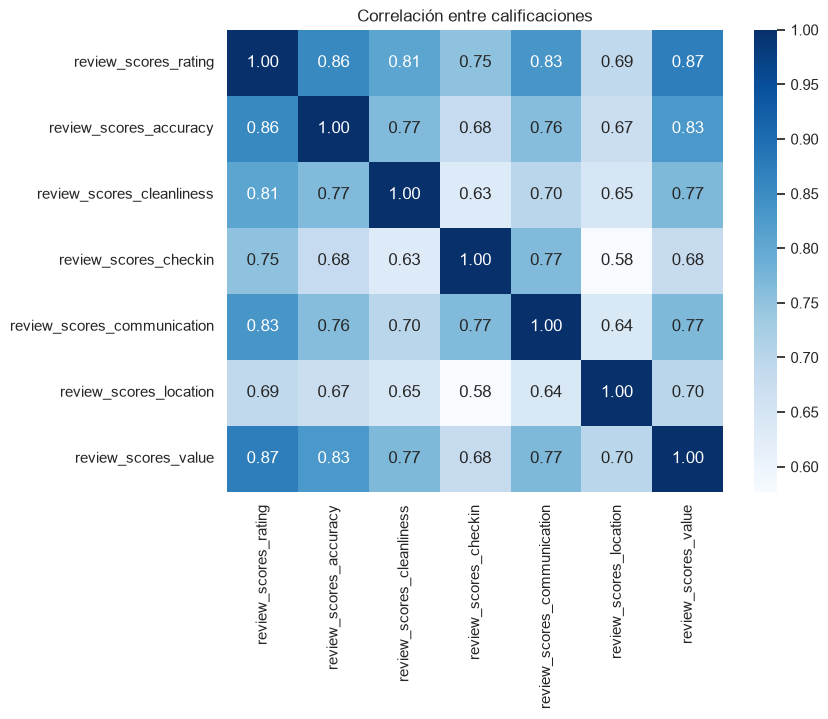

In [30]:
plt.figure(figsize=(8, 6))
sns.heatmap(con_res[scores].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Correlación entre calificaciones')
plt.show()

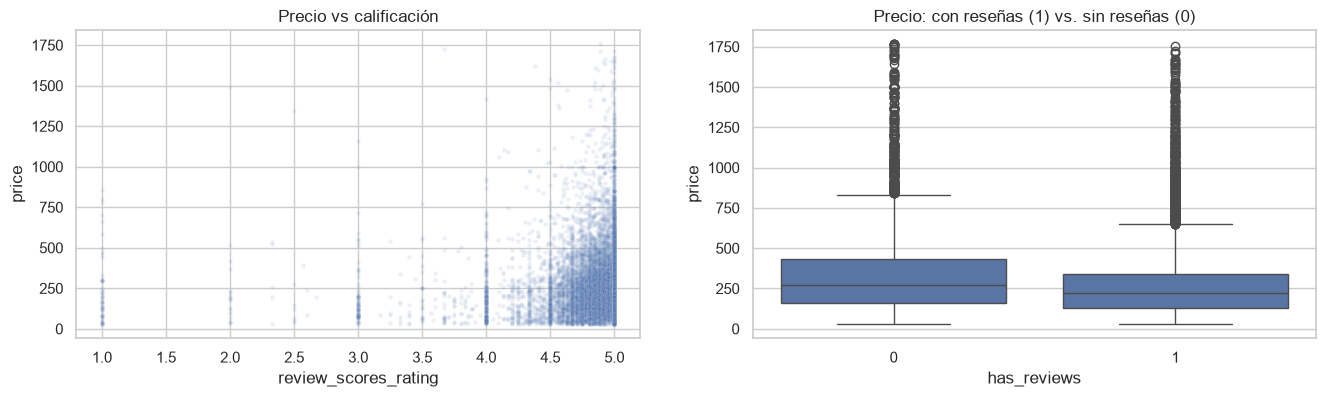

Correlación (Spearman) calificación-precio: 0.1


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.scatterplot(data=con_res, x='review_scores_rating', y='price', alpha=0.1, s=10, ax=ax[0])
ax[0].set_title('Precio vs calificación')
sns.boxplot(data=df, x='has_reviews', y='price', ax=ax[1])
ax[1].set_title('Precio: con reseñas (1) vs. sin reseñas (0)')
plt.show()

print("Correlación (Spearman) calificación-precio:",
      round(con_res[['review_scores_rating', 'price']].corr('spearman').iloc[0, 1], 2))


Calificaciones muy altas: el 74 % de los anuncios (12.096) tiene reseñas. En las 7 calificaciones la mediana está entre 4,85 y 4,96 y el 25 % tiene 5,0 perfecto. La más baja es relación calidad-precio (4,85) y las más altas comunicación (4,96) y check-in (4,95).
Números redondos (1, 2, 3, 4): son anuncios con muy pocas reseñas, donde una sola reseña define la calificación. Por eso, para la etiqueta de recomendable se exige un mínimo de reseñas.
Por tipo de habitación: vivienda completa y habitación privada califican cerca de 4,9; habitación compartida y de hotel califican más bajo (cerca de 4,4).
Las 7 calificaciones van juntas (correlación de 0,58 a 0,87). La general resume bien a las demás, sobre todo a calidad-precio (0,87) y exactitud (0,86), así que basta con usar la general.
Calificación y precio no se relacionan: hay anuncios baratos y caros con 5,0. Además, los anuncios sin reseñas cobran un poco más que los que tienen reseñas. Precio y recomendación son preguntas distintas.

## 14. Ocupación y disponibilidad
La ocupación estimada indica cuánto se renta un anuncio. Revisamos si los anuncios mejor calificados se ocupan más.

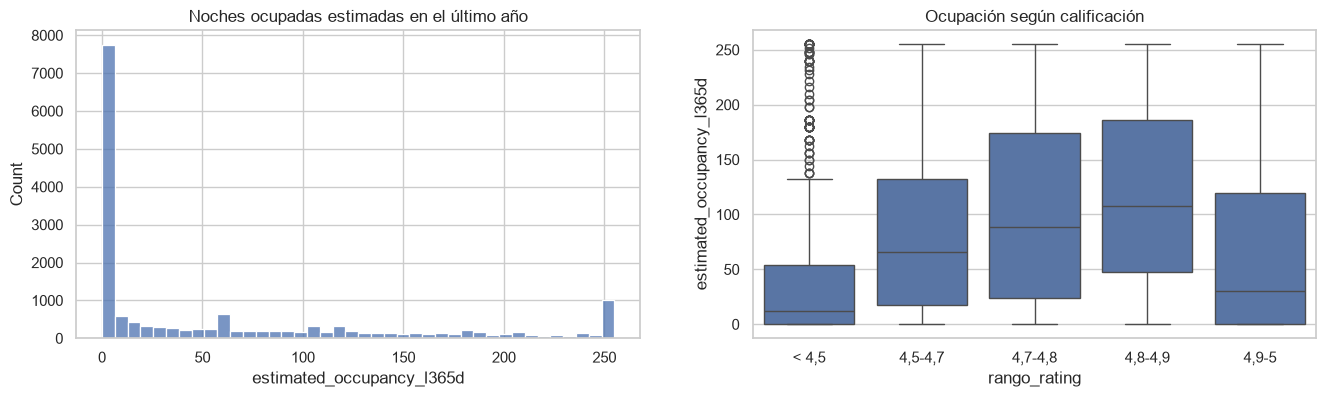

In [31]:
con_res['rango_rating'] = pd.cut(con_res['review_scores_rating'], bins=[0, 4.5, 4.7, 4.8, 4.9, 5],
                                 labels=['< 4,5', '4,5-4,7', '4,7-4,8', '4,8-4,9', '4,9-5'])

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(df['estimated_occupancy_l365d'], bins=40, ax=ax[0])
ax[0].set_title('Noches ocupadas estimadas en el último año')
sns.boxplot(data=con_res, x='rango_rating', y='estimated_occupancy_l365d', ax=ax[1])
ax[1].set_title('Ocupación según calificación')
plt.show()


Ocupación: unos 7.700 anuncios (casi la mitad) no se rentaron ninguna noche el último año, y unos 1.000 llegan al máximo (255 noches).
La ocupación sube con la calificación: la mediana pasa de unas 12 noches (menos de 4,5) a 65 (4,5–4,7), 88 (4,7–4,8) y 108 (4,8–4,9). Los huéspedes eligen más los anuncios mejor calificados.
Excepción en 4,9–5: la ocupación baja a unas 30 noches. Muchos anuncios con calificación perfecta tienen pocas reseñas y se rentan poco (son nuevos o casi inactivos), así que una calificación de 5,0 sola no basta.
Implicación: para la etiqueta de recomendable no basta con una calificación alta; también hay que ver varias reseñas y que el anuncio esté activo. 

## 15. Nuevas características
- **log_price:** logaritmo del precio, para la regresión.
- **price_per_guest:** precio por huésped.
- **dist_strip_km:** distancia al Strip en km.
- **host_profesional:** 1 si el anfitrión tiene 10 o más anuncios.
- **rating_promedio:** promedio de las 7 calificaciones.
- **recomendable:** 1 = sí, 0 = no, vacío = sin reseñas; para la clasificación.

In [32]:
df['log_price'] = np.log(df['price'])
df['price_per_guest'] = df['price'] / df['accommodates']
df['rating_promedio'] = df[scores].mean(axis=1, skipna=False)

df[['log_price', 'price_per_guest', 'dist_strip_km', 'host_profesional', 'rating_promedio']].describe().round(2)

,log_price,price_per_guest,dist_strip_km,host_profesional,rating_promedio
count,16434.00,16434.00,16434.00,16434.00,12095.00
mean,5.39,57.66,7.90,0.47,4.81
std,0.77,53.46,14.37,0.50,0.34
min,3.33,6.21,0.08,0.00,1.00
25%,4.92,31.50,1.43,0.00,4.78
50%,5.45,45.93,5.18,0.00,4.88
75%,5.89,66.00,9.81,1.00,4.95
max,7.48,1688.00,127.58,1.00,5.00


### Propuesta de etiqueta "recomendable"
Un anuncio es **recomendable** si cumple las tres condiciones:
1. Calificación general de **4,8 o más** (está por encima de lo normal, que ya es alto).
2. Al menos **5 reseñas**, para que la calificación sea confiable.
3. Al menos **1 reseña en el último año**, para que el anuncio siga activo y la calificación esté vigente.

Los anuncios sin reseñas quedan vacíos: no hay información para decir si son recomendables o no. Los umbrales son una propuesta y se pueden ajustar con el equipo de clasificación.

In [34]:
cond = ((df['review_scores_rating'] >= 4.8) &
        (df['number_of_reviews'] >= 5) &
        (df['number_of_reviews_ltm'] >= 1))

df['recomendable'] = cond.astype(float)
df.loc[df['has_reviews'] == 0, 'recomendable'] = np.nan

print(df['recomendable'].value_counts(dropna=False))
print("\n% recomendables (entre los que tienen reseñas):",
      round(df['recomendable'].mean() * 100, 1))

recomendable
0.0    6618
1.0    5478
NaN    4338
Name: count, dtype: int64

% recomendables (entre los que tienen reseñas): 45.3


Nuevas variables: el anuncio típico cobra $46 por huésped y está a 5,2 km del Strip; el 47 % de los anuncios es de anfitriones profesionales y el promedio de calificaciones típico es 4,88.
Recomendable: de los 12.096 anuncios con reseñas, 5.478 son recomendables (45 %) y 6.618 no (55 %). Los 4.338 sin reseñas quedan vacíos.
Los dos grupos están bastante equilibrados.

## 16. ¿En qué se diferencian los anuncios recomendables?
Comparamos los anuncios recomendables y no recomendables en precio, tamaño, comodidades y anfitrión.

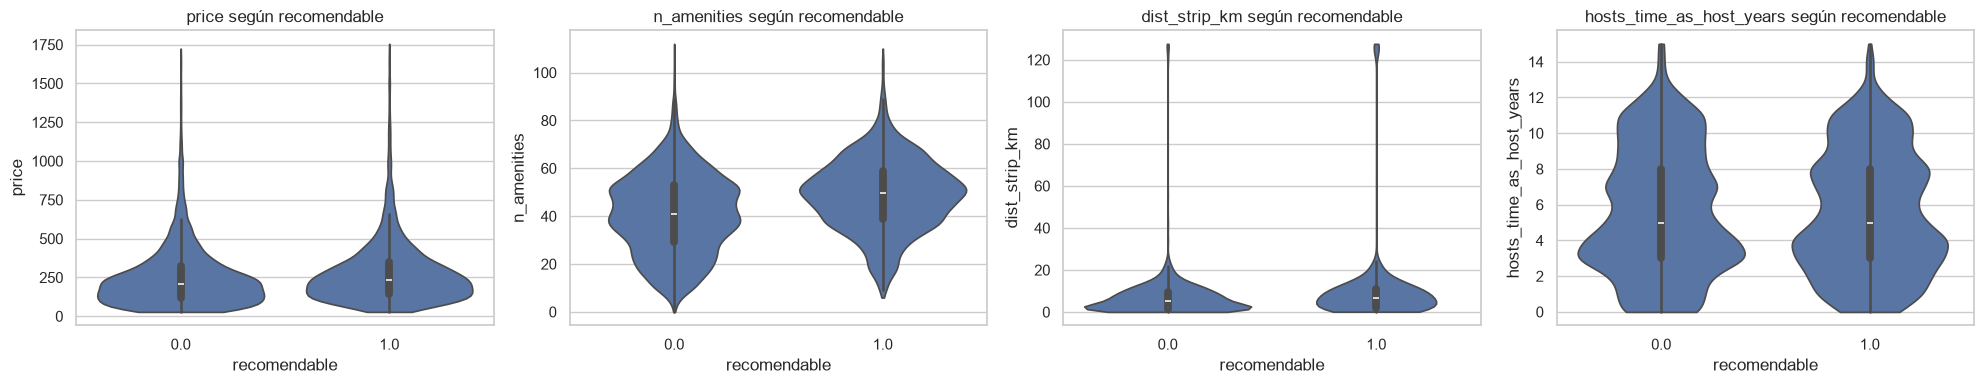

In [35]:
eti = df.dropna(subset=['recomendable'])

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for col, ax in zip(['price', 'n_amenities', 'dist_strip_km', 'hosts_time_as_host_years'], axes):
    sns.violinplot(data=eti, x='recomendable', y=col, cut=0, ax=ax)
    ax.set_title(f'{col} según recomendable')
plt.tight_layout()
plt.show()

In [36]:
comparar = ['price', 'accommodates', 'n_amenities', 'dist_strip_km', 'host_is_superhost',
            'host_profesional', 'has_self_checkin', 'has_pool', 'has_workspace', 'minimum_nights']
eti.groupby('recomendable')[comparar].mean().T.round(2)

recomendable,0.0,1.0
price,254.62,283.46
accommodates,5.56,6.35
n_amenities,40.69,48.91
dist_strip_km,7.35,9.95
host_is_superhost,0.36,0.76
host_profesional,0.48,0.38
has_self_checkin,0.71,0.83
has_pool,0.66,0.59
has_workspace,0.61,0.67
minimum_nights,8.12,4.51


## 17. Dataset para modelos
Guardamos el dataset con las nuevas características. Se quitan las columnas de texto que creamos solo para graficar (los dummies originales siguen en el archivo).

In [37]:
df_final = df.drop(columns=['tipo_habitacion', 'tipo_propiedad', 'zona', 'rango_dist'])

print("Shape final:", df_final.shape)
print("Columnas nuevas:", ['log_price', 'price_per_guest', 'dist_strip_km',
                           'host_profesional', 'rating_promedio', 'recomendable'])
print("Columnas de texto:", df_final.select_dtypes('object').shape[1])

df_final.to_csv('listings_clark_eda.csv', index=False)

Shape final: (16434, 63)
Columnas nuevas: ['log_price', 'price_per_guest', 'dist_strip_km', 'host_profesional', 'rating_promedio', 'recomendable']
Columnas de texto: 0


In [39]:
# Guardar el archivo 
df_final.to_csv('listings_clark_eda.csv', index=False)